### Caricamento dati e analisi struttura 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Carico dataset 
df = pd.read_csv('C:/Users/filip/Documents/neuroimaging-oasis-pipeline/data/raw/oasis_cross-sectional-5708aa0a98d82080.csv', sep=';')

# Mostro le prime righe e le info generali
print(df.info())
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 436 entries, 0 to 435
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   ID      436 non-null    str    
 1   M/F     436 non-null    str    
 2   Hand    436 non-null    str    
 3   Age     436 non-null    int64  
 4   Educ    235 non-null    float64
 5   SES     216 non-null    float64
 6   MMSE    235 non-null    float64
 7   CDR     235 non-null    float64
 8   eTIV    436 non-null    int64  
 9   nWBV    436 non-null    float64
 10  ASF     436 non-null    float64
 11  Delay   20 non-null     float64
dtypes: float64(7), int64(2), str(3)
memory usage: 41.0 KB
None


,ID,M/F,Hand,Age,Educ,SES,MMSE,CDR,eTIV,nWBV,ASF,Delay
0,OAS1_0001_MR1,F,R,74,2.0,3.0,29.0,0.0,1344,0.743,1.306,NaN
1,OAS1_0002_MR1,F,R,55,4.0,1.0,29.0,0.0,1147,0.810,1.531,NaN
2,OAS1_0003_MR1,F,R,73,4.0,3.0,27.0,0.5,1454,0.708,1.207,NaN
3,OAS1_0004_MR1,M,R,28,NaN,NaN,NaN,NaN,1588,0.803,1.105,NaN
4,OAS1_0005_MR1,M,R,18,NaN,NaN,NaN,NaN,1737,0.848,1.010,NaN


In [2]:
# Controlla quanti valori nulli ci sono per colonna
print(df.isnull().sum())

ID         0
M/F        0
Hand       0
Age        0
Educ     201
SES      220
MMSE     201
CDR      201
eTIV       0
nWBV       0
ASF        0
Delay    416
dtype: int64


In [3]:
# Verifico nome delle colonne e il conteggio dei valori nulli

print("--- Valori mancanti per colonna ---")
print(df.isnull().sum())

print("\n--- Distribuzione dei valori CDR ---")
print(df['CDR'].value_counts(dropna=False))

print("\n--- Numero totale di soggetti ---")
print(f"Totale righe: {len(df)}")

--- Valori mancanti per colonna ---
ID         0
M/F        0
Hand       0
Age        0
Educ     201
SES      220
MMSE     201
CDR      201
eTIV       0
nWBV       0
ASF        0
Delay    416
dtype: int64

--- Distribuzione dei valori CDR ---
CDR
NaN    201
0.0    135
0.5     70
1.0     28
2.0      2
Name: count, dtype: int64

--- Numero totale di soggetti ---
Totale righe: 436


### Pulizia dati e definizione del target

In [ ]:
# 1. Teniamo solo i soggetti che hanno il CDR valutato
df_clean = df.dropna(subset=['CDR']).copy()

# 2. Trasformiamo in numeri puliti e definiamo il target: 0 = Sano, 1 = Demente/MCI
df_clean['CDR'] = df_clean['CDR'].astype(float)
df_clean['target'] = (df_clean['CDR'] > 0).astype(int)

# 3. Convertiamo le colonne numeriche se necessario e gestiamo i valori nulli residui 
for col in ['Age', 'Educ', 'SES', 'MMSE', 'eTIV', 'nWBV', 'ASF']:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# 4. Verifica bilanciamento del target
print("Distribuzione Target (0 = Sano, 1 = Demente/MCI):")
print(df_clean['target'].value_counts())

Distribuzione Target (0 = Sano, 1 = Demente/MCI):
target
0    135
1    100
Name: count, dtype: int64


### Visualizzazione grafica delle variabili chiave

C:\Users\filip\AppData\Local\Temp\ipykernel_14820\2617201967.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='target', y='nWBV', ax=axes[0], palette=['#2ecc71', '#e74c3c'])
C:\Users\filip\AppData\Local\Temp\ipykernel_14820\2617201967.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['Sano (0)', 'Demente (1)'])
C:\Users\filip\AppData\Local\Temp\ipykernel_14820\2617201967.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='target', y='MMSE', ax=axes[1], palette=['#2ecc71', '#e74c3c'])
C:\Users\filip\AppData\

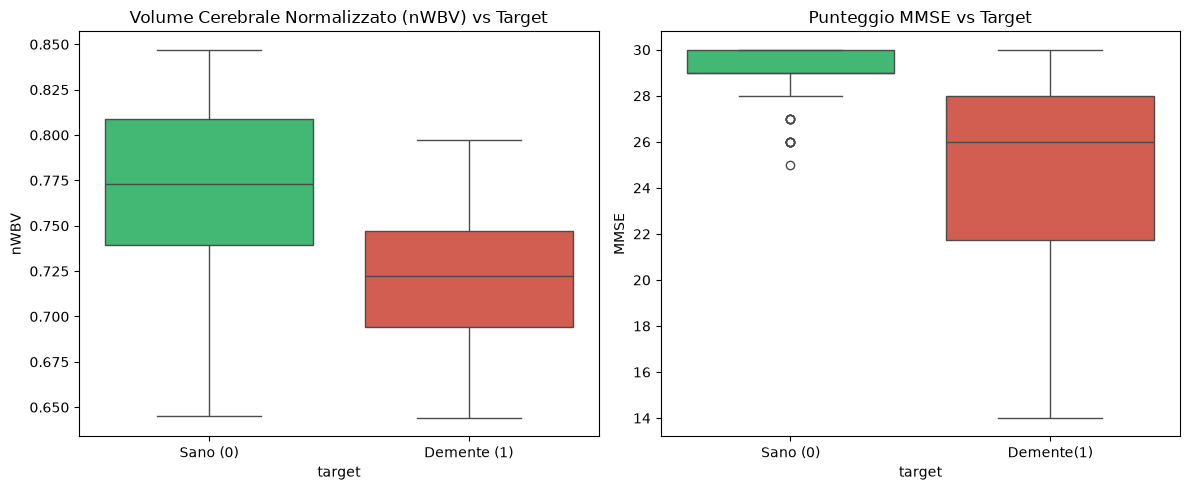

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))

# Boxplot nWBV vs Target
sns.boxplot(data=df_clean, x='target', y='nWBV', ax=axes[0], palette=['#2ecc71', '#e74c3c'])
axes[0].set_title('Volume Cerebrale Normalizzato (nWBV) vs Target')
axes[0].set_xticklabels(['Sano (0)', 'Demente (1)'])

# Boxplot MMSE vs Target 
sns.boxplot(data=df_clean, x='target', y='MMSE', ax=axes[1], palette=['#2ecc71', '#e74c3c'])
axes[1].set_title('Punteggio MMSE vs Target')
axes[1].set_xticklabels(['Sano (0)', 'Demente(1)'])

plt.tight_layout()
plt.show()

### Costruzione primo modello (Random Forest e Logistic Regression)

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Selezione delle feature quantitative
features = ['Age', 'Educ', 'SES', 'MMSE', 'eTIV', 'nWBV', 'ASF']
X = df_clean[features]
y = df_clean['target']

# Split Train / Test (80% training, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Addestramento Random Forest 
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Predizione 
y_pred = rf_model.predict(X_test)

# Valutazione
print("--- Accuracy ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2%}\n")

print("---Classification report---")
print(classification_report(y_test, y_pred, target_names=['Sano', 'Demente']))

--- Accuracy ---
Accuracy: 85.11%

---Classification report---
              precision    recall  f1-score   support

        Sano       0.83      0.93      0.88        27
     Demente       0.88      0.75      0.81        20

    accuracy                           0.85        47
   macro avg       0.86      0.84      0.84        47
weighted avg       0.85      0.85      0.85        47



## Analisi feature importance

C:\Users\filip\AppData\Local\Temp\ipykernel_14820\1187956243.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_imp_df, x='Importance', y='Feature', palette='viridis')


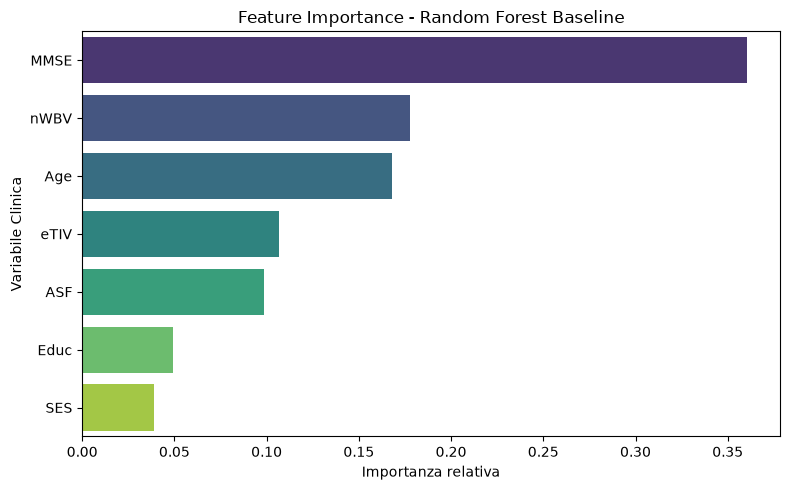

In [8]:
# Estrazione dell'importanza delle feature
importances = rf_model.feature_importances_
feature_imp_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Grafico a barre
plt.figure(figsize=(8,5))
sns.barplot(data=feature_imp_df, x='Importance', y='Feature', palette='viridis')
plt.title('Feature Importance - Random Forest Baseline')
plt.xlabel('Importanza relativa')
plt.ylabel('Variabile Clinica')
plt.tight_layout()
plt.show()